<a href="https://colab.research.google.com/github/sreya2702/NASAExoplanetDiscoveryAnalytics/blob/master/nasa_exoplanet_discovery_analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

import plotly.express as px
import plotly.graph_objects as go

import requests
from io import StringIO

import sqlite3

from scipy import stats

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
BASE_URL = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"

In [ ]:
columns = [
    # Identification
    "pl_name",
    "hostname",
    "gaia_dr3_id",

    # Discovery information
    "discoverymethod",
    "disc_year",
    "disc_facility",
    "disc_locale",
    "disc_telescope",

    # System information
    "sy_pnum",
    "sy_snum",
    "sy_dist",

    # Planet properties
    "pl_orbper",
    "pl_orbsmax",
    "pl_rade",
    "pl_bmasse",
    "pl_eqt",
    "pl_orbeccen",
    "pl_insol",

    # Host-star properties
    "st_teff",
    "st_rad",
    "st_mass",
    "st_met"
]

print("Number of selected columns:", len(columns))

Number of selected columns: 22


In [ ]:
query = f"""
SELECT {','.join(columns)}
FROM pscomppars
"""

print(query)


SELECT pl_name,hostname,gaia_dr3_id,discoverymethod,disc_year,disc_facility,disc_locale,disc_telescope,sy_pnum,sy_snum,sy_dist,pl_orbper,pl_orbsmax,pl_rade,pl_bmasse,pl_eqt,pl_orbeccen,pl_insol,st_teff,st_rad,st_mass,st_met
FROM pscomppars



In [ ]:
params = {
    "query": query,
    "format": "csv"
}

response = requests.get(
    BASE_URL,
    params=params,
    timeout=60
)

response.raise_for_status()

df = pd.read_csv(StringIO(response.text))

print("NASA data downloaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

NASA data downloaded successfully!
Rows: 6451
Columns: 22


In [ ]:
df.head()

,pl_name,hostname,gaia_dr3_id,discoverymethod,disc_year,disc_facility,disc_locale,disc_telescope,sy_pnum,sy_snum,sy_dist,pl_orbper,pl_orbsmax,pl_rade,pl_bmasse,pl_eqt,pl_orbeccen,pl_insol,st_teff,st_rad,st_mass,st_met
0,55 Cnc b,55 Cnc,Gaia DR3 704967037090946688,Radial Velocity,1996,Lick Observatory,Ground,3.0 m C. Donald Shane Telescope,7,2,12.5855,14.651552,0.11800,13.900,263.9785,700.00,0.0029,45.6336,5198.0,0.980,1.015,0.39
1,55 Cnc c,55 Cnc,Gaia DR3 704967037090946688,Radial Velocity,2004,McDonald Observatory,Ground,9.2 m Hobby-Eberly Telescope,7,2,12.5855,44.393600,0.24700,8.510,54.4738,499.27,0.0880,10.4149,5198.0,0.980,1.015,0.39
2,55 Cnc d,55 Cnc,Gaia DR3 704967037090946688,Radial Velocity,2002,Lick Observatory,Ground,3.0 m C. Donald Shane Telescope,7,2,12.5855,4799.000000,5.60000,13.000,1232.4930,104.85,0.0913,0.0203,5198.0,0.980,1.015,0.39
3,55 Cnc e,55 Cnc,Gaia DR3 704967037090946688,Radial Velocity,2004,McDonald Observatory,Ground,9.2 m Hobby-Eberly Telescope,7,2,12.5855,0.736547,0.01544,1.875,7.9900,1958.00,0.0500,2657.8322,5172.0,0.943,0.905,0.35
4,55 Cnc f,55 Cnc,Gaia DR3 704967037090946688,Radial Velocity,2007,Multiple Observatories,Ground,Multiple Telescopes,7,2,12.5855,260.580000,0.80200,7.590,44.8120,277.07,0.0630,0.9879,5198.0,0.980,1.015,0.39


In [ ]:
df.tail()

,pl_name,hostname,gaia_dr3_id,discoverymethod,disc_year,disc_facility,disc_locale,disc_telescope,sy_pnum,sy_snum,sy_dist,pl_orbper,pl_orbsmax,pl_rade,pl_bmasse,pl_eqt,pl_orbeccen,pl_insol,st_teff,st_rad,st_mass,st_met
6446,TOI-426 b,TOI-426,Gaia DR3 2983316311375470976,Transit,2026,Transiting Exoplanet Survey Satellite (TESS),Space,0.1 m TESS Telescope,2,1,113.590,1.320503,0.02374,2.190000,6.700000,1790.00,NaN,1711.0000,5750.00,0.990000,1.000,0.16
6447,TOI-435 b,TOI-435,Gaia DR3 5082797618168232320,Transit,2026,Transiting Exoplanet Survey Satellite (TESS),Space,0.1 m TESS Telescope,1,1,165.285,3.352919,NaN,4.030000,15.300000,753.66,0.00,76.2487,4040.00,0.672832,0.632,NaN
6448,TOI-1873 b,TOI-1873,Gaia DR3 1725869974390536832,Transit,2026,Transiting Exoplanet Survey Satellite (TESS),Space,0.1 m TESS Telescope,1,1,182.014,7.005727,NaN,2.863564,8.570000,923.50,NaN,171.8936,5597.99,0.971675,1.015,NaN
6449,HD 715 b,HD 715,Gaia DR3 2741377642494388864,Transit,2026,Transiting Exoplanet Survey Satellite (TESS),Space,0.1 m TESS Telescope,1,2,167.253,56.400000,0.33600,11.993609,201.821038,798.00,0.21,67.3000,6070.00,2.500000,1.600,0.09
6450,TOI-426 c,TOI-426,Gaia DR3 2983316311375470976,Radial Velocity,2026,La Silla Observatory,Ground,3.6 m ESO Telescope,2,1,113.590,235.800000,0.74700,13.600000,444.000000,319.20,NaN,1.7300,5750.00,0.990000,1.000,0.16


In [ ]:
df.sample(10, random_state=42)

,pl_name,hostname,gaia_dr3_id,discoverymethod,disc_year,disc_facility,disc_locale,disc_telescope,sy_pnum,sy_snum,sy_dist,pl_orbper,pl_orbsmax,pl_rade,pl_bmasse,pl_eqt,pl_orbeccen,pl_insol,st_teff,st_rad,st_mass,st_met
1726,GJ 251 b,GJ 251,Gaia DR3 939072613334579328,Radial Velocity,2020,W. M. Keck Observatory,Ground,10 m Keck I Telescope,2,1,5.58057,14.237000,0.08080,1.790000,3.850000,336.0,0.00,2.3700,3342.0,0.360,0.350,0.070
4975,Kepler-519 b,Kepler-519,Gaia DR3 2075161655782111872,Transit,2016,Kepler,Space,0.95 m Kepler Telescope,1,2,246.61000,24.307895,0.15932,2.100000,5.060000,532.0,0.00,19.8700,5260.0,0.800,0.890,0.010
4763,Kepler-1907 c,Kepler-1907,Gaia DR3 2119409512668086656,Transit,2021,Kepler,Space,0.95 m Kepler Telescope,2,1,292.11100,14.863900,0.10371,1.155470,1.630000,620.0,0.00,20.6000,5159.0,0.800,0.752,-0.160
4266,TOI-5789 b,TOI-5789,NaN,Radial Velocity,2026,Multiple Observatories,Ground,Multiple Telescopes,4,1,20.45810,2.763690,0.03608,1.260000,2.120000,1201.0,0.00,360.2797,5185.0,0.833,0.821,-0.120
5683,TOI-1752 b,TOI-1752,Gaia DR3 1438168463332034816,Transit,2026,Transiting Exoplanet Survey Satellite (TESS),Space,0.1 m TESS Telescope,2,1,103.02100,0.935186,0.01624,1.693000,3.510000,1036.0,NaN,194.1729,3762.0,0.530,0.524,-0.110
4695,Kepler-704 b,Kepler-704,Gaia DR3 2104530027969874944,Transit,2016,Kepler,Space,0.95 m Kepler Telescope,1,1,1228.83000,3.761821,0.04700,2.610000,7.320000,1121.0,0.00,514.1240,5616.0,0.960,0.970,0.090
401,WASP-38 b,WASP-38,Gaia DR3 4453211899986180352,Transit,2010,SuperWASP,Ground,Canon 200mm f/1.8L,1,1,136.24000,6.871880,0.07522,13.787070,1093.335200,1250.0,0.03,501.5014,6180.0,1.520,1.760,-0.020
3372,TOI-2876 b,TOI-2876,Gaia DR3 2929750922377138816,Transit,2025,Transiting Exoplanet Survey Satellite (TESS),Space,0.1 m TESS Telescope,1,1,225.74400,6.299643,0.06540,9.639723,54.030829,929.0,0.13,124.2000,5271.0,0.873,0.939,0.353
1328,Kepler-83 c,Kepler-83,Gaia DR3 2105261134483173632,Transit,2012,Kepler,Space,0.95 m Kepler Telescope,3,2,400.40900,20.090000,0.11796,2.360000,2.030000,362.0,0.00,5.9000,4082.0,0.610,0.660,-0.200
3975,Kepler-1302 b,Kepler-1302,Gaia DR3 2130136176312202624,Transit,2016,Kepler,Space,0.95 m Kepler Telescope,1,1,634.58000,8.839227,0.07950,1.430000,2.630000,778.0,0.00,58.3440,5236.0,0.820,0.860,0.040


In [ ]:
print("Dataset shape:", df.shape)

print("\nNumber of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset shape: (6451, 22)

Number of rows: 6451
Number of columns: 22


In [ ]:
df.columns.tolist()

['pl_name',
 'hostname',
 'gaia_dr3_id',
 'discoverymethod',
 'disc_year',
 'disc_facility',
 'disc_locale',
 'disc_telescope',
 'sy_pnum',
 'sy_snum',
 'sy_dist',
 'pl_orbper',
 'pl_orbsmax',
 'pl_rade',
 'pl_bmasse',
 'pl_eqt',
 'pl_orbeccen',
 'pl_insol',
 'st_teff',
 'st_rad',
 'st_mass',
 'st_met']

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6451 entries, 0 to 6450
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pl_name          6451 non-null   object 
 1   hostname         6451 non-null   object 
 2   gaia_dr3_id      6053 non-null   object 
 3   discoverymethod  6451 non-null   object 
 4   disc_year        6451 non-null   int64  
 5   disc_facility    6451 non-null   object 
 6   disc_locale      6451 non-null   object 
 7   disc_telescope   6451 non-null   object 
 8   sy_pnum          6451 non-null   int64  
 9   sy_snum          6451 non-null   int64  
 10  sy_dist          6423 non-null   float64
 11  pl_orbper        6097 non-null   float64
 12  pl_orbsmax       5956 non-null   float64
 13  pl_rade          6401 non-null   float64
 14  pl_bmasse        6421 non-null   float64
 15  pl_eqt           5911 non-null   float64
 16  pl_orbeccen      5383 non-null   float64
 17  pl_insol      

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
disc_year,6451.0,2017.403038,5.202505e+00,1992.000000,2014.000000,2016.00000,2021.000000,2.026000e+03
sy_pnum,6451.0,1.753372,1.145981e+00,1.000000,1.000000,1.00000,2.000000,8.000000e+00
sy_snum,6451.0,1.101225,3.389222e-01,1.000000,1.000000,1.00000,1.000000,4.000000e+00
sy_dist,6423.0,704.833229,1.230179e+03,1.301190,99.643550,349.00000,817.261000,8.500000e+03
pl_orbper,6097.0,70215.799122,5.150759e+06,0.090706,4.288178,10.64130,37.993273,4.020000e+08
pl_orbsmax,5956.0,15.423953,3.454552e+02,0.004400,0.052285,0.10275,0.313000,1.900000e+04
pl_rade,6401.0,5.844661,5.400441e+00,0.309800,1.850000,2.86000,11.900000,8.720587e+01
pl_bmasse,6421.0,402.686345,1.141945e+03,0.020000,4.350000,9.32000,189.101000,1.265150e+04
pl_eqt,5911.0,836.377171,4.957499e+02,1.480000,486.185000,758.00000,1095.000000,7.777780e+03
pl_orbeccen,5383.0,0.079107,1.524384e-01,0.000000,0.000000,0.00000,0.090000,9.500000e-01


In [ ]:
raw_df = df.copy()

print("Raw dataset preserved.")

Raw dataset preserved.


In [ ]:
print(raw_df.shape)

(6451, 22)


In [ ]:
duplicate_planets = df.duplicated(subset="pl_name").sum()

print("Duplicate planet names:", duplicate_planets)

Duplicate planet names: 0


In [ ]:
df[df.duplicated(subset="pl_name", keep=False)]

,pl_name,hostname,gaia_dr3_id,discoverymethod,disc_year,disc_facility,disc_locale,disc_telescope,sy_pnum,sy_snum,sy_dist,pl_orbper,pl_orbsmax,pl_rade,pl_bmasse,pl_eqt,pl_orbeccen,pl_insol,st_teff,st_rad,st_mass,st_met


In [ ]:
missing_values = df.isnull().sum()

missing_percentage = (
    df.isnull().sum() / len(df) * 100
)

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

missing_report = missing_report.sort_values(
    "Missing Percentage",
    ascending=False
)

missing_report

,Missing Values,Missing Percentage
pl_orbeccen,1068,16.555573
st_met,699,10.835529
pl_insol,596,9.238878
pl_eqt,540,8.370795
pl_orbsmax,495,7.673229
gaia_dr3_id,398,6.169586
pl_orbper,354,5.487521
st_rad,332,5.146489
st_teff,307,4.758952
pl_rade,50,0.775074


In [ ]:
missing_report["Missing Percentage"] = (
    missing_report["Missing Percentage"].round(2)
)

missing_report

,Missing Values,Missing Percentage
pl_orbeccen,1068,16.56
st_met,699,10.84
pl_insol,596,9.24
pl_eqt,540,8.37
pl_orbsmax,495,7.67
gaia_dr3_id,398,6.17
pl_orbper,354,5.49
st_rad,332,5.15
st_teff,307,4.76
pl_rade,50,0.78


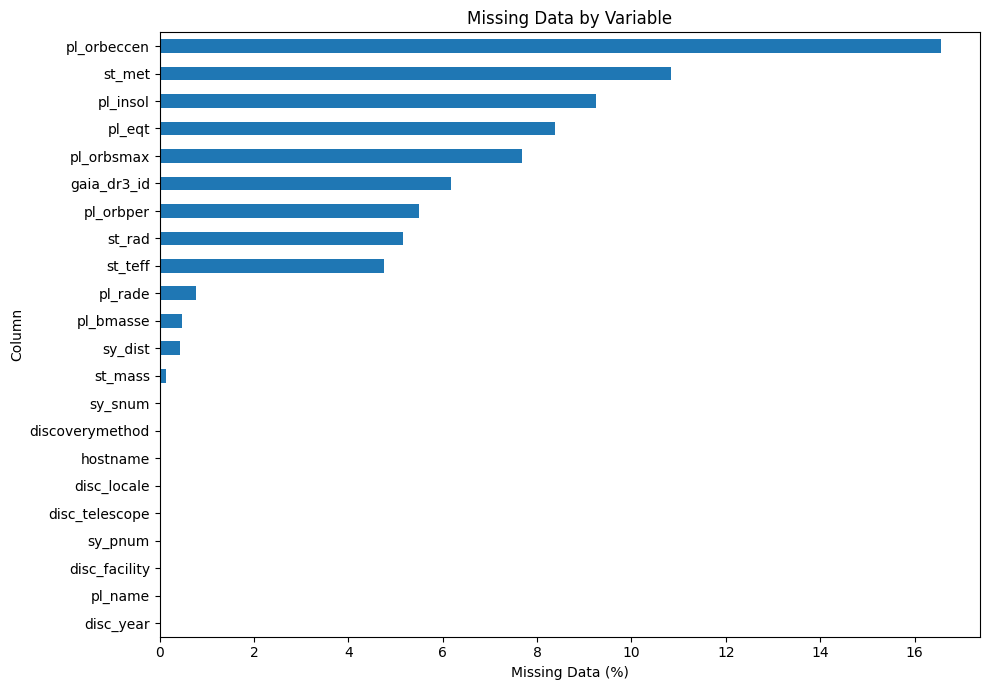

In [ ]:
plt.figure(figsize=(10, 7))

missing_report["Missing Percentage"].sort_values().plot(
    kind="barh"
)

plt.xlabel("Missing Data (%)")
plt.ylabel("Column")
plt.title("Missing Data by Variable")

plt.tight_layout()
plt.show()

In [ ]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
)

df.columns.tolist()

['pl_name',
 'hostname',
 'gaia_dr3_id',
 'discoverymethod',
 'disc_year',
 'disc_facility',
 'disc_locale',
 'disc_telescope',
 'sy_pnum',
 'sy_snum',
 'sy_dist',
 'pl_orbper',
 'pl_orbsmax',
 'pl_rade',
 'pl_bmasse',
 'pl_eqt',
 'pl_orbeccen',
 'pl_insol',
 'st_teff',
 'st_rad',
 'st_mass',
 'st_met']

In [ ]:
numeric_columns = [
    "disc_year",
    "sy_pnum",
    "sy_snum",
    "sy_dist",
    "pl_orbper",
    "pl_orbsmax",
    "pl_rade",
    "pl_bmasse",
    "pl_eqt",
    "pl_orbeccen",
    "pl_insol",
    "st_teff",
    "st_rad",
    "st_mass",
    "st_met"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

In [ ]:
df[numeric_columns].dtypes

,0
disc_year,int64
sy_pnum,int64
sy_snum,int64
sy_dist,float64
pl_orbper,float64
pl_orbsmax,float64
pl_rade,float64
pl_bmasse,float64
pl_eqt,float64
pl_orbeccen,float64


In [ ]:
df["disc_year"].describe()

,disc_year
count,6451.000000
mean,2017.403038
std,5.202505
min,1992.000000
25%,2014.000000
50%,2016.000000
75%,2021.000000
max,2026.000000


In [ ]:
df["disc_year"].describe()

,disc_year
count,6451.000000
mean,2017.403038
std,5.202505
min,1992.000000
25%,2014.000000
50%,2016.000000
75%,2021.000000
max,2026.000000
